# UrbanHub — Partie 1 : flux batch, analyse météorologique

Données : NOAA Global Hourly, stations situées en France, 5 dernières années.
Pré-requis : avoir lancé `python -m src.batch_noaa.download` puis `python -m src.batch_noaa.clean` depuis la racine du repo.

In [1]:
# ── Imports ──
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

from src.batch_noaa import config
from src.batch_noaa.clean import daily_precipitation, local_date

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
FIG_DIR = ROOT / "reports" / "figures" / "partie1"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# ── Chargement des données nettoyées ──
cols = ["station_id", "station_name", "city", "latitude", "longitude", "timestamp",
        "temperature", "dew_point", "wind_speed", "wind_direction", "pressure",
        "visibility", "precipitation", "precipitation_period_h"]
df = pd.read_parquet(config.PROCESSED_DIR, columns=cols)
df["date"] = local_date(df["timestamp"])

print(f"{len(df):,} observations horaires, {df['station_id'].nunique()} stations")
print("période :", df["timestamp"].min(), "->", df["timestamp"].max())
df.describe().round(1)

0 observations horaires, 0 stations
période : NaT -> NaT


,latitude,longitude,temperature,dew_point,wind_speed,wind_direction,pressure,visibility,precipitation,precipitation_period_h,date
count,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


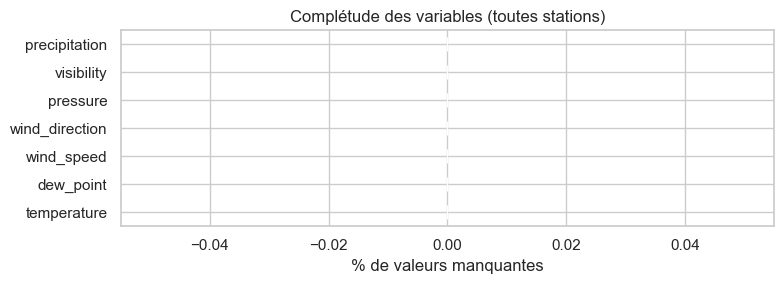

In [3]:
# ── Qualité : taux de valeurs manquantes après nettoyage ──
vars_ = ["temperature", "dew_point", "wind_speed", "wind_direction", "pressure", "visibility", "precipitation"]
missing = df[vars_].isna().mean().mul(100).sort_values()
ax = missing.plot.barh(color="steelblue", figsize=(8, 3))
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Complétude des variables (toutes stations)")
plt.tight_layout(); plt.savefig(FIG_DIR / "00_completude.png", dpi=120); plt.show()

La pluie est très incomplète au niveau horaire : elle n'est déclarée que dans certains messages (SYNOP), en cumul sur 1h, 3h, 6h, 12h ou 24h selon la station. On la reconstruit donc en cumul journalier (`daily_precipitation`).

In [4]:
# ── Agrégation journalière par station ──
daily = (df.groupby(["station_id", "date"])
           .agg(t_mean=("temperature", "mean"), t_min=("temperature", "min"),
                t_max=("temperature", "max"), wind_mean=("wind_speed", "mean"),
                wind_max=("wind_speed", "max"), p_mean=("pressure", "mean"),
                p_min=("pressure", "min"), vis_mean=("visibility", "mean"),
                vis_min=("visibility", "min"), n_obs=("temperature", "count"))
           .reset_index())
daily = daily[daily["n_obs"] >= 16]          # au moins 16 heures de mesures dans la journée
daily = daily.merge(daily_precipitation(df), on=["station_id", "date"], how="left")
daily["city"] = daily["station_id"].map(config.CITY_STATIONS)
print(f"{len(daily):,} journées-station exploitables")
daily.head()

0 journées-station exploitables


,station_id,date,t_mean,t_min,t_max,wind_mean,wind_max,p_mean,p_min,vis_mean,vis_min,n_obs,precipitation_day,city


## Q1 — Peut-on identifier des périodes météorologiques anormales ?

Méthode : pour chaque station, on calcule une « normale » de température journalière : médiane et écart-type robuste (IQR) de toutes les valeurs observées à ±15 jours de la même date, sur les 5 ans. La médiane évite qu'une canicule ou une vague de froid déforme la normale. L'écart à cette normale, en nombre d'écarts-types (z-score), est ensuite moyenné sur toute la France. Une période anormale = au moins 3 jours consécutifs avec |z| ≥ 1.5.

In [5]:
# ── Normales saisonnières par station (robustes aux événements extrêmes) ──
daily["doy"] = daily["date"].dt.dayofyear.clip(upper=365)
W = 15   # fenêtre de ±15 jours autour de chaque jour de l'année

clims = []
for st, g in daily.groupby("station_id"):
    piv = g.pivot_table(index="doy", columns=g["date"].dt.year, values="t_mean").reindex(range(1, 366))
    if piv.notna().sum().sum() < 300:      # pas assez d'historique pour une normale fiable
        continue
    arr = piv.to_numpy()
    ext = np.vstack([arr[-W:], arr, arr[:W]])                         # année circulaire
    win = np.stack([ext[i:i + 2 * W + 1].ravel() for i in range(365)])  # toutes les valeurs de la fenêtre
    q25, med, q75 = np.nanpercentile(win, [25, 50, 75], axis=1)
    # médiane et écart-type robuste (IQR) : une canicule ne déforme pas la normale
    clims.append(pd.DataFrame({"station_id": st, "doy": range(1, 366),
                               "clim_mean": med, "clim_std": np.maximum((q75 - q25) / 1.349, 0.5)}))
clim = pd.concat(clims)
daily = daily.merge(clim, on=["station_id", "doy"], how="left")
daily["t_anom"] = daily["t_mean"] - daily["clim_mean"]
daily["t_z"] = daily["t_anom"] / daily["clim_std"]

ValueError: No objects to concatenate

In [ ]:
# ── Indice national et détection des périodes ──
nat = daily.groupby("date").agg(t_z=("t_z", "mean"), t_anom=("t_anom", "mean"),
                                n_stations=("station_id", "nunique"))
nat["flag"] = np.sign(nat["t_z"]).where(nat["t_z"].abs() >= 1.5, 0)

# regroupe les jours consécutifs de même signe
run_id = (nat["flag"] != nat["flag"].shift()).cumsum()
periods = (nat[nat["flag"] != 0].groupby(run_id[nat["flag"] != 0])
             .agg(debut=("t_z", lambda s: s.index.min()), fin=("t_z", lambda s: s.index.max()),
                  jours=("t_z", "size"), z_max=("t_z", lambda s: s.abs().max()),
                  ecart_moyen_C=("t_anom", "mean")))
periods = periods[periods["jours"] >= 3].copy()
periods["type"] = np.where(periods["ecart_moyen_C"] > 0, "chaud", "froid")
periods = periods.sort_values("z_max", ascending=False).reset_index(drop=True)
periods.round(2)

In [ ]:
# ── Visualisation ──
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(nat.index, nat["t_z"], lw=0.6, color="grey")
ax.plot(nat.index, nat["t_z"].rolling(7, center=True).mean(), lw=1.2, color="black", label="moyenne 7 j")
for _, r in periods.iterrows():
    ax.axvspan(r["debut"], r["fin"], color="red" if r["type"] == "chaud" else "blue", alpha=0.25)
ax.axhline(1.5, ls="--", c="red", lw=0.8); ax.axhline(-1.5, ls="--", c="blue", lw=0.8)
ax.set_ylabel("écart à la normale (z)")
ax.set_title("Anomalies de température en France — périodes anormales en couleur")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "q1_anomalies_temperature.png", dpi=120); plt.show()

Complément multivariable : une Isolation Forest repère les journées atypiques en combinant température, vent, pression, pluie et visibilité (et pas seulement la température).

In [ ]:
# ── Isolation Forest sur les journées nationales ──
feat = daily.groupby("date").agg(t_z=("t_z", "mean"), wind_max=("wind_max", "mean"),
                                 p_min=("p_min", "mean"), precip=("precipitation_day", "mean"),
                                 vis_min=("vis_min", "mean")).dropna()
iso = IsolationForest(contamination=0.02, random_state=0).fit(feat)
feat["score"] = -iso.score_samples(feat)
feat["anomalie"] = iso.predict(feat[["t_z", "wind_max", "p_min", "precip", "vis_min"]]) == -1
print(f"{feat['anomalie'].sum()} journées atypiques sur {len(feat)}")
feat.sort_values("score", ascending=False).head(15).round(2)

## Q2 — Existe-t-il une corrélation entre conditions météo et visibilité ?

In [ ]:
# ── Humidité relative (formule de Magnus) et écart température / point de rosée ──
def rel_humidity(t, td):
    return 100 * np.exp(17.625 * td / (243.04 + td)) / np.exp(17.625 * t / (243.04 + t))

h = df.dropna(subset=["visibility", "temperature", "dew_point"]).copy()
if len(h) > 2_000_000:
    h = h.sample(2_000_000, random_state=0)
h["humidity"] = rel_humidity(h["temperature"], h["dew_point"])
h["spread"] = h["temperature"] - h["dew_point"]

corr = h[["visibility", "humidity", "spread", "temperature", "wind_speed", "pressure"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Corrélations de Spearman (données horaires)")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_correlations.png", dpi=120); plt.show()

In [ ]:
# ── Visibilité selon l'humidité et selon la pluie du jour ──
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

h["classe_humidite"] = pd.cut(h["humidity"], [0, 60, 80, 90, 95, 100.1],
                              labels=["<60", "60-80", "80-90", "90-95", ">95"])
sns.boxplot(data=h, x="classe_humidite", y="visibility", showfliers=False, ax=axes[0])
axes[0].set(xlabel="humidité relative (%)", ylabel="visibilité (km)", title="Visibilité vs humidité")

d = daily.dropna(subset=["precipitation_day", "vis_mean"]).copy()
d["classe_pluie"] = pd.cut(d["precipitation_day"], [-0.1, 0.1, 2, 10, 30, 1000],
                           labels=["sec", "0-2", "2-10", "10-30", ">30"])
sns.boxplot(data=d, x="classe_pluie", y="vis_mean", showfliers=False, ax=axes[1])
axes[1].set(xlabel="pluie du jour (mm)", ylabel="visibilité moyenne (km)", title="Visibilité vs pluie")
plt.tight_layout(); plt.savefig(FIG_DIR / "q2_visibilite_humidite_pluie.png", dpi=120); plt.show()

In [ ]:
# ── Fréquence du brouillard (visibilité < 1 km) par mois et par heure locale ──
h["mois"] = h["timestamp"].dt.tz_convert("Europe/Paris").dt.month
h["heure"] = h["timestamp"].dt.tz_convert("Europe/Paris").dt.hour
fog = h.assign(brouillard=h["visibility"] < 1).pivot_table(index="mois", columns="heure",
                                                           values="brouillard", aggfunc="mean") * 100
sns.heatmap(fog, cmap="Greys", cbar_kws={"label": "% d'observations < 1 km"})
plt.title("Fréquence du brouillard"); plt.tight_layout()
plt.savefig(FIG_DIR / "q2_brouillard_mois_heure.png", dpi=120); plt.show()

## Q3 — Évolution saisonnière de la température en France et dans les principales villes

In [ ]:
# ── Moyennes mensuelles ──
m = df.dropna(subset=["temperature"]).copy()
m["mois"] = m["date"].values.astype("datetime64[M]")

france = m.groupby("mois")["temperature"].mean()
villes = m[m["city"].notna()].groupby(["mois", "city"])["temperature"].mean().unstack()

fig, ax = plt.subplots(figsize=(14, 5))
villes.plot(ax=ax, lw=1, alpha=0.8)
france.plot(ax=ax, lw=3, color="black", label="France (toutes stations)")
ax.set(ylabel="température moyenne (°C)", xlabel="", title="Température moyenne mensuelle")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "q3_temperature_mensuelle.png", dpi=120); plt.show()

In [ ]:
# ── Cycle saisonnier moyen par ville (heatmap ville x mois) ──
m["num_mois"] = m["date"].dt.month
cycle = m[m["city"].notna()].pivot_table(index="city", columns="num_mois",
                                         values="temperature", aggfunc="mean")
cycle = cycle.loc[cycle.mean(axis=1).sort_values().index]
sns.heatmap(cycle, annot=True, fmt=".0f", cmap="coolwarm")
plt.title("Cycle saisonnier moyen (°C)"); plt.xlabel("mois"); plt.ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "q3_cycle_saisonnier_villes.png", dpi=120); plt.show()

amplitude = (cycle.max(axis=1) - cycle.min(axis=1)).sort_values()
print("amplitude saisonnière (mois le plus chaud - mois le plus froid, °C) :")
print(amplitude.round(1).to_string())

In [ ]:
# ── Tendance par saison et par année (France) ──
saison = {12: "hiver", 1: "hiver", 2: "hiver", 3: "printemps", 4: "printemps", 5: "printemps",
          6: "été", 7: "été", 8: "été", 9: "automne", 10: "automne", 11: "automne"}
m["saison"] = m["num_mois"].map(saison)
m["annee_saison"] = m["date"].dt.year + (m["num_mois"] == 12)   # décembre compté avec l'hiver suivant
s = m.pivot_table(index="annee_saison", columns="saison", values="temperature", aggfunc="mean")
s[["hiver", "printemps", "été", "automne"]].round(1)

## Q4 — Quels sont les jours présentant des conditions météorologiques extrêmes ?

Deux approches :
- **seuils absolus** inspirés de la vigilance Météo-France : Tmax ≥ 35 °C, Tmin ≤ -10 °C, vent moyen horaire ≥ 15 m/s (54 km/h), pluie ≥ 50 mm/jour, brouillard dense (visibilité < 200 m) ;
- **seuils relatifs** à chaque station (percentiles 99 / 1), pour tenir compte du climat local (35 °C n'a pas le même sens à Brest et à Nîmes).

In [ ]:
# ── Seuils absolus ──
crit = {
    "canicule": daily["t_max"] >= 35,
    "grand_froid": daily["t_min"] <= -10,
    "vent_fort": daily["wind_max"] >= 15,
    "fortes_pluies": daily["precipitation_day"] >= 50,
    "brouillard_dense": daily["vis_min"] < 0.2,
}
for k, v in crit.items():
    daily[k] = v.fillna(False)
types = list(crit)

par_jour = daily.groupby("date")[types].sum()
par_jour["stations_touchees"] = daily.assign(x=daily[types].any(axis=1)).groupby("date")["x"].sum()
par_jour["part_stations_%"] = 100 * par_jour["stations_touchees"] / daily.groupby("date")["station_id"].nunique()
top = par_jour.sort_values("part_stations_%", ascending=False).head(20)
top.round(1)

In [ ]:
# ── Seuils relatifs (percentiles par station) ──
q = daily.groupby("station_id").agg(tmax99=("t_max", lambda s: s.quantile(0.99)),
                                    tmin01=("t_min", lambda s: s.quantile(0.01)),
                                    wind99=("wind_max", lambda s: s.quantile(0.99)),
                                    rain99=("precipitation_day", lambda s: s.quantile(0.99)))
d = daily.merge(q, on="station_id")
d["score_extreme"] = ((d["t_max"] >= d["tmax99"]).astype(int) + (d["t_min"] <= d["tmin01"]).astype(int)
                      + (d["wind_max"] >= d["wind99"]).astype(int)
                      + (d["precipitation_day"] >= d["rain99"]).astype(int))
rel = d.groupby("date")["score_extreme"].mean().sort_values(ascending=False)
print("journées les plus extrêmes relativement aux climats locaux :")
rel.head(15).round(3)

In [ ]:
# ── Nombre de journées-station extrêmes par mois et par type ──
mensuel = daily.groupby(daily["date"].values.astype("datetime64[M]"))[types].sum()
mensuel.index = pd.to_datetime(mensuel.index).strftime("%Y-%m")
mensuel.plot.bar(stacked=True, figsize=(14, 4), width=0.9)
plt.xticks(range(0, len(mensuel), 3), mensuel.index[::3], rotation=45)
plt.ylabel("journées-station"); plt.title("Événements extrêmes par mois")
plt.tight_layout(); plt.savefig(FIG_DIR / "q4_extremes_par_mois.png", dpi=120); plt.show()

In [ ]:
# ── Export des résultats pour la partie 4 (analyse croisée) ──
out = config.PROCESSED_DIR.parent / "noaa_daily.parquet"
daily.drop(columns=["doy"]).to_parquet(out, index=False)
periods.to_csv(ROOT / "reports" / "partie1_periodes_anormales.csv", index=False)
top.to_csv(ROOT / "reports" / "partie1_jours_extremes.csv")
print("exporté :", out)

## Interprétation

À rédiger après exécution sur les vraies données :
- **Q1** : quelles périodes ressortent (dates, chaud/froid) ? Correspondent-elles à des événements connus (canicules, vagues de froid) ?
- **Q2** : quelle variable explique le mieux la visibilité ? (attendu : l'humidité / l'écart T-Td, bien plus que le vent ou la pression) ; à quels mois et heures le brouillard est-il le plus fréquent ?
- **Q3** : amplitude saisonnière par ville (climat océanique vs continental vs méditerranéen), années plus chaudes que d'autres ?
- **Q4** : jours les plus extrêmes et type d'événement dominant.